<a href="https://colab.research.google.com/github/saisreekalivarapu/AML-LAB/blob/main/AML_LAB_EXP2_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Data Preparation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

### 2. Prepare Data

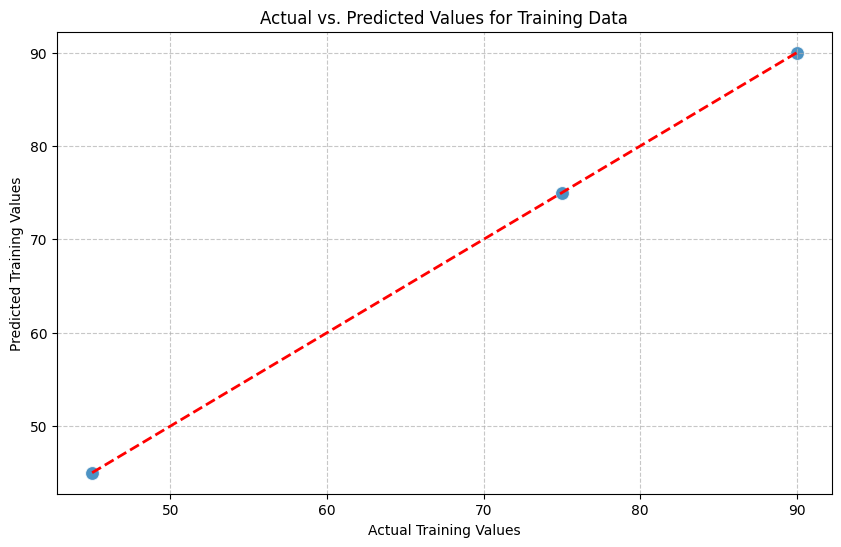

In [ ]:
y_train_pred = model.predict(X_train)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_train, y=y_train_pred, alpha=0.8, s=100)
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--', lw=2)
plt.xlabel("Actual Training Values")
plt.ylabel("Predicted Training Values")
plt.title("Actual vs. Predicted Values for Training Data")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
X = data[['Study_Hours', 'Attendance', 'Assignment']]
y = data['Final_Marks']


if len(data) > 1:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
else:
    X_train, X_test, y_train, y_test = X, X, y, y # Use full data for both if only one sample

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 3 samples
Testing set size: 1 samples


In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model training complete.")
print(f"Model coefficients: {model.coef_}")
print(f"Model intercept: {model.intercept_}")

Model training complete.
Model coefficients: [7.50000000e+00 1.66756719e-16 6.67026876e-17]
Model intercept: 29.999999999999993


### The Multiple Linear Regression Formula

The multiple linear regression model predicts the dependent variable (final marks) based on a linear combination of independent variables (study hours, attendance, assignment). The general form of the equation is:

$$ y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n + \epsilon $$

Where:
- $y$ is the predicted dependent variable (e.g., `Final_Marks`).
- $\beta_0$ is the y-intercept (the value of $y$ when all independent variables are zero). In the output, this is `Model intercept: 29.99...`.
- $\beta_1, \beta_2, \dots, \beta_n$ are the coefficients for each independent variable. These represent the change in $y$ for a one-unit change in the corresponding $x_i$, holding all other variables constant. In the output, these are `Model coefficients: [7.50e+00 1.66e-16 6.67e-17]`.
- $x_1, x_2, \dots, x_n$ are the independent variables (e.g., `Study_Hours`, `Attendance`, `Assignment`).
- $\epsilon$ is the error term, representing the difference between the actual and predicted values.

In our case, the model learned an equation like:
`Final Marks = 30.00 + 7.50 * Study_Hours + (approx. 0) * Attendance + (approx. 0) * Assignment`

In [ ]:
y_pred = model.predict(X_test)

print("Predictions made on the test set.")
print("Actual values (test set):\n", y_test)
print("Predicted values (test set):\n", y_pred)

Predictions made on the test set.
Actual values (test set):
 1    60
Name: Final_Marks, dtype: int64
Predicted values (test set):
 [60.]


In [ ]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2) Score: {r2:.2f}")

Mean Squared Error (MSE): 0.00
Mean Absolute Error (MAE): 0.00
Root Mean Squared Error (RMSE): 0.00
R-squared (R2) Score: nan


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


### Evaluation Metrics Formulas

Here are the formulas for the evaluation metrics used to assess the regression model's performance:

1.  **Mean Squared Error (MSE)**
    Measures the average of the squares of the errors—the average squared difference between the estimated values and actual value.
    $$ \text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 $$
    Where:
    - $n$ is the number of data points.
    - $y_i$ is the actual value.
    - $\hat{y}_i$ is the predicted value.

2.  **Mean Absolute Error (MAE)**
    Measures the average of the absolute differences between predictions and actual observations. It gives an idea of the magnitude of the errors without considering their direction.
    $$ \text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i| $$

3.  **Root Mean Squared Error (RMSE)**
    The square root of the MSE. It has the same units as the dependent variable, making it more interpretable than MSE.
    $$ \text{RMSE} = \sqrt{\text{MSE}} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 }$$

4.  **R-squared ($R^2$) Score**
    Represents the proportion of the variance in the dependent variable that is predictable from the independent variables. It's a measure of how well the model fits the observed data.
    $$ R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2} = 1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}} $$
    Where:
    - $\text{SS}_{\text{res}}$ (Sum of Squares of Residuals) is the sum of the squared differences between actual and predicted values.
    - $\text{SS}_{\text{tot}}$ (Total Sum of Squares) is the sum of the squared differences between actual values and their mean ($\bar{y}$).

    *Note: The warning `R^2 score is not well-defined with less than two samples` occurs because the formula for $R^2$ involves a sum of squares, and with only one test sample, the denominator (total sum of squares) becomes zero, leading to an undefined value.*

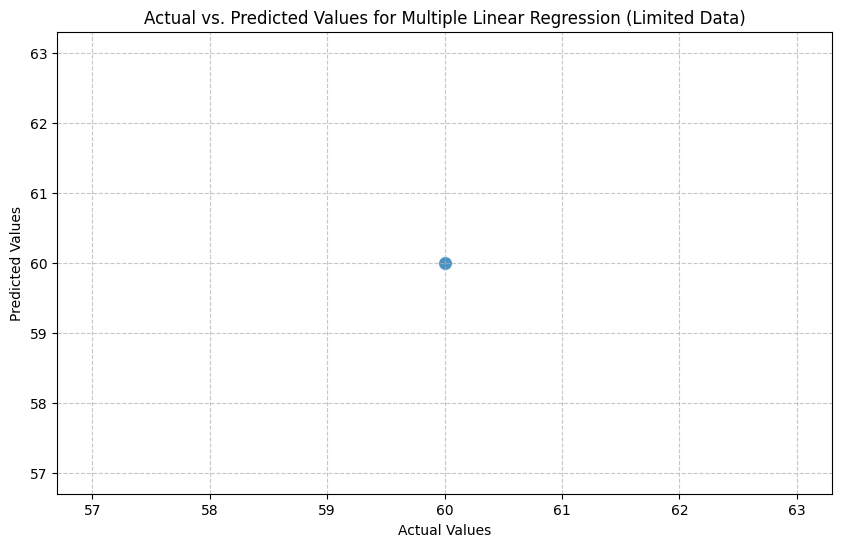

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.8, s=100)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs. Predicted Values for Multiple Linear Regression (Limited Data)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
study_hours = [2, 4, 6, 8]
attendance = [70, 80, 85, 90]
assignment = [12, 15, 18, 20]
final_marks = [45, 60, 75, 90]

data = pd.DataFrame({
    'Study_Hours': study_hours,
    'Attendance': attendance,
    'Assignment': assignment,
    'Final_Marks': final_marks
})

print("Prepared Data Head:")
display(data.head())

Prepared Data Head:


,Study_Hours,Attendance,Assignment,Final_Marks
0,2,70,12,45
1,4,80,15,60
2,6,85,18,75
3,8,90,20,90


### 5. Evaluate Model

### 6. Visualize Results

### 3. Split Data

### 4. Train Model

### 7. Visualize Training Data: Actual vs. Predicted

This new plot displays the actual versus predicted values for the training data. The points represent each training sample, and the red dashed line indicates where perfect predictions would lie. The closer the points are to this line, the better the model's fit on the training data. This gives a better visual representation of the linear regression model's learned relationship.

## Kernel State
Here are some of the notable variables in the kernel:
Variable #1
name: `X`, type: `DataFrame`
value:
```
   Study_Hours  Attendance  Assignment
0            2          70          12
1            4          80          15
2            6          85          18
3            8          90          20
```
Variable #2
name: `X1`, type: `ndarray`
value:
```
array([3.74540119, 9.50714306, 7.31993942, 5.98658484, 1.5601864 ,
       1.5599452 , 0.58083612, 8.66176146, 6.01115012, 7.08072578,
       0.20584494, 9.69909852, 8.32442641, 2.12339111, 1.81824967,
       1.8340451 , 3.04242243, 5.24756432, 4.31945019, 2.9122914 ,
       6.11852895, 1.39493861, 2.92144649, 3.66361843, 4.56069984,
       7.85175961, 1.99673782, 5.14234438, 5.92414569, 0.46450413,
       6.07544852, 1.70524124, 0.65051593, 9.48885537, 9.65632033,<TRUNCATED original_length=1340>
```
Variable #3
name: `X2`, type: `ndarray`
value:
```
array([0.15714593, 3.18205206, 1.57177991, 2.54285346, 4.53783237,
       1.24646115, 2.05191462, 3.77775569, 1.14399083, 0.38489955,
       1.44875726, 0.80610644, 4.64848826, 4.0406019 , 3.16701878,
       4.35730295, 4.01836038, 0.93285029, 4.46279499, 2.69671121,
       4.03720078, 4.4804565 , 1.59001737, 0.55025962, 1.13967581,
       2.13553894, 4.09007383, 4.30365292, 0.03476065, 2.55373651,
       2.08705502, 1.11053905, 0.59932684, 1.68807586, 4.71454852,<TRUNCATED original_length=1340>
```
Variable #4
name: `X3`, type: `ndarray`
value:
```
array([12.84063292,  1.6827993 ,  3.23257428, 17.97108377, 12.12858119,
        0.18394103,  2.02943086, 13.27003538,  0.10123168,  3.21616103,
       10.97467579, 13.83790395, 13.03922519,  4.48538619, 14.24358443,
        4.74498175,  6.50799396, 14.9298281 , 12.99265798, 16.98446821,
       13.15225785, 11.36617207,  1.87349536,  7.35431606,  5.30404735,
        4.87979287, 19.4602111 ,  7.86195449, 17.8409311 , 12.62277252,
       15.89622607, 10.05274186, 11.<TRUNCATED original_length=1440>
```
Variable #5
name: `X_test`, type: `DataFrame`
value:
```
   Study_Hours  Attendance  Assignment
1            4          80          15
```
Variable #6
name: `X_train`, type: `DataFrame`
value:
```
   Study_Hours  Attendance  Assignment
3            8          90          20
0            2          70          12
2            6          85          18
```
Variable #7
name: `data`, type: `DataFrame`
value:
```
   Study_Hours  Attendance  Assignment  Final_Marks
0            2          70          12           45
1            4          80          15           60
2            6          85          18           75
3            8          90          20           90
```
Variable #8
name: `y`, type: `Series`
value:
```
0    45
1    60
2    75
3    90
Name: Final_Marks, dtype: int64
```
Variable #9
name: `y_pred`, type: `ndarray`
value: `array([60.])`
Variable #10
name: `y_test`, type: `Series`
value:
```
1    60
Name: Final_Marks, dtype: int64
```
Variable #11
name: `y_train`, type: `Series`
value:
```
3    90
0    45
2    75
Name: Final_Marks, dtype: int64
```
Variable #12
name: `y_train_pred`, type: `ndarray`
value: `array([90., 45., 75.])`
Variable #13
name: `assignment`, type: `list`
value: `[12, 15, 18, 20]`
Variable #14
name: `attendance`, type: `list`
value: `[70, 80, 85, 90]`
Variable #15
name: `final_marks`, type: `list`
value: `[45, 60, 75, 90]`
Variable #16
name: `mae`, type: `float`
value: `0.0`
Variable #17
name: `mse`, type: `float`
value: `0.0`
Variable #18
name: `n_samples`, type: `int`
value: `100`
Variable #19
name: `r2`, type: `float`
value: `nan`
Variable #20
name: `rmse`, type: `float64`
value: `np.float64(0.0)`
Variable #21
name: `study_hours`, type: `list`
value: `[2, 4, 6, 8]`